In [227]:
import pandas as pd
import numpy as np 
import matplotlib.pylab as plt

data = pd.read_parquet("data/allen_data.parquet")
sessions = data['ophys_session_id'].unique()

session_0 = data[data['ophys_session_id'] == sessions[0]]
neurons_count_0 = session_0['cell_specimen_id'].nunique()
presentations = session_0['stimulus_presentations_id'].unique()
presentations_count_0 = session_0['stimulus_presentations_id'].nunique()
presentations_0 = session_0['stimulus_presentations_id'].unique()
image_ids = session_0['image_name'].unique()


subd = session_0.pivot(index = 'cell_specimen_id', columns = ['stimulus_presentations_id', 'image_name'], values = 'mean_response')
dic = {}
for i, image_id in enumerate(image_ids):
    r = subd.loc[:, pd.IndexSlice[:, image_ids[i]]]
    mea = r.mean(axis = 1)
    dic[image_id] = np.array(mea)


df = pd.DataFrame(dic, index = subd.index)
display(df)
M = np.array(df)


,im075,omitted,im000,im054,im035,im045,im106,im073,im031
cell_specimen_id,,,,,,,,,
1086496500,0.018066,-0.026186,0.043965,0.039543,0.042555,0.030621,-0.001272,0.054493,0.006353
1086496689,0.028118,-0.040192,0.087711,0.074114,0.027132,0.082804,0.000182,0.226830,0.020698
1086497034,0.003710,-0.017744,0.013108,0.030075,0.016565,0.033371,0.002354,0.065402,0.000340
1086497129,0.053566,-0.070710,0.121126,0.088034,0.098208,0.117583,0.001380,0.429036,0.042969
1086497438,0.039172,-0.041251,0.057211,0.082717,0.062743,0.051971,0.005431,0.123318,0.029556
1086497908,0.031740,-0.027899,0.028597,0.093153,0.092873,0.024469,-0.001309,0.032523,-0.001897
1086498071,0.033037,-0.027685,0.041798,0.018273,0.021287,-0.005675,0.012564,0.040379,-0.002819
1086498820,0.187483,-0.030422,0.070449,0.154899,0.084039,0.162346,0.048923,0.279396,0.041396
1086498977,0.005898,-0.032720,0.048113,0.040675,0.094416,0.067014,0.003266,0.077600,0.003810


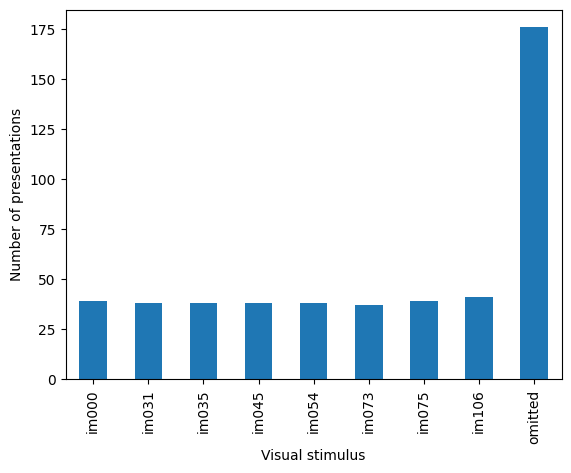

In [228]:
counts = (
    session_0.groupby("image_name")["stimulus_presentations_id"]
    .nunique()
)

counts.plot(kind="bar")
plt.xlabel("Visual stimulus")
plt.ylabel("Number of presentations")
plt.show()

In [229]:
sss = []
for session in sessions:
    session_mask = data['ophys_session_id'] == session
    subset = data[session_mask]
    nneurons = subset['cell_specimen_id'].nunique()
    nsims = subset['stimulus_presentations_id'].nunique()
    nimages = subset['image_name'].nunique()
    session_nrows = subset.shape[0]
    ary = np.array([session, nneurons, nsims, nimages, session_nrows])
    sss.append(ary)

aaa = np.array(sss)
dff = pd.DataFrame(aaa)
dff.columns = ['Session ID', 'Neurons', 'Presentations', 'Image labels', 'Rows']
display(dff)



,Session ID,Neurons,Presentations,Image labels,Rows
0,994199725,17,484,9,8228
1,994731371,13,478,9,6214
2,994883056,16,442,9,7072
3,933463604,17,448,9,7616
4,967200850,21,442,9,9282
5,967965969,22,478,9,10516
6,993231283,15,380,9,5700
7,993668836,13,379,9,4927
8,957189583,18,498,9,8964
9,992783847,18,315,9,5670


In [230]:

duplicates = data.duplicated(['ophys_session_id', 'cell_specimen_id', 'stimulus_presentations_id'])
print(duplicates.sum())
print(data['mean_response'].isna().sum())
print(data['ophys_session_id'].isna().sum())
print(data['cell_specimen_id'].isna().sum())
print(data['stimulus_presentations_id'].isna().sum())


print(session_0[['stimulus_presentations_id', 'image_name']].drop_duplicates()['image_name'].value_counts(dropna = False))

display(session_0[[ 'stimulus_presentations_id', 'image_name']].drop_duplicates())

d = data[['ophys_session_id', 'stimulus_presentations_id', 'image_name']]
labels_per_presentation = d.groupby(['ophys_session_id', 'stimulus_presentations_id'])['image_name'].nunique(dropna=False)

print(labels_per_presentation)
print((labels_per_presentation == 1).all())


0
0
0
0
0
image_name
omitted    176
im106       41
im075       39
im000       39
im054       38
im035       38
im045       38
im031       38
im073       37
Name: count, dtype: int64


,stimulus_presentations_id,image_name
85,5,im075
187,11,omitted
238,14,omitted
544,32,im000
765,45,omitted
...,...,...
81243,4779,omitted
81294,4782,omitted
81345,4785,im054
81583,4799,im000


ophys_session_id  stimulus_presentations_id
933463604         1                            1
                  6                            1
                  35                           1
                  48                           1
                  58                           1
                                              ..
1010684546        4766                         1
                  4769                         1
                  4781                         1
                  4789                         1
                  4803                         1
Name: image_name, Length: 9686, dtype: int64
True


In [231]:
H = data[['cell_specimen_id', 'ophys_session_id', 'stimulus_presentations_id', 'image_name']]
n_neurons = np.array(H.groupby(['ophys_session_id'])['cell_specimen_id'].nunique())
H = H.drop_duplicates(subset=H.columns.difference(['cell_specimen_id']))

r = pd.DataFrame(H.groupby(['ophys_session_id'])['image_name'].value_counts())
r = r.reset_index()

R = r.pivot(columns='image_name', index='ophys_session_id', values='count').fillna(0).astype(int)
display(R)


L = R.drop(columns='omitted')
o = L[L != 0]
image_count = o.notna().sum(axis = 1)
min_arr = np.nanmin(o, axis = 1).astype(int)
k = pd.DataFrame({'neurons_count' : n_neurons, 'image_count' : image_count ,'min_image_repetition' : min_arr}, index=L.index, dtype = int)
k = k.sort_values(by='min_image_repetition', ascending=False)
display(k)

image_name,im000,im031,im035,im045,im054,im061,im062,im063,im065,im066,im069,im073,im075,im077,im085,im106,omitted
ophys_session_id,,,,,,,,,,,,,,,,,
933463604,30,32,31,29,31,0,0,0,0,0,0,32,31,0,0,32,200
957189583,39,39,37,41,40,0,0,0,0,0,0,38,39,0,0,39,186
961180142,12,13,11,11,12,0,0,0,0,0,0,10,12,0,0,9,147
961665529,16,16,15,15,15,0,0,0,0,0,0,15,14,0,0,16,153
963496285,0,0,0,0,0,14,14,14,13,13,14,0,0,14,14,0,169
967200850,32,33,34,33,34,0,0,0,0,0,0,33,34,0,0,34,175
967965969,0,0,0,0,0,38,35,36,38,39,38,0,0,39,39,0,176
979379271,26,27,27,28,28,0,0,0,0,0,0,28,27,0,0,27,183
981863572,0,0,0,0,0,23,22,24,23,23,24,0,0,24,25,0,179


,neurons_count,image_count,min_image_repetition
ophys_session_id,,,
1005018474,35,8,42
1004317427,25,8,40
994199725,17,8,37
957189583,18,8,37
994731371,13,8,36
967965969,22,8,35
994883056,16,8,35
967200850,21,8,32
933463604,17,8,29


In [232]:
candidate = data[data['ophys_session_id'] == 1005018474]
print(candidate['ophys_experiment_id'].isna().sum())
print(data['image_name'].isna().sum())

print(candidate['ophys_experiment_id'].nunique())
print(candidate['cell_specimen_id'].nunique())
print(candidate['stimulus_presentations_id'].nunique())
ll = data[['cell_specimen_id', 'stimulus_presentations_id', 'ophys_experiment_id']]
display(ll.groupby('ophys_experiment_id')[['cell_specimen_id', 'stimulus_presentations_id']].nunique().sort_values(by='cell_specimen_id', ascending=False))


w = candidate[['cell_specimen_id', 'stimulus_presentations_id', 'mean_response', 'image_name']]

w = w.drop(w[w['image_name'] == 'omitted'].index)
ss = w.pivot(index='cell_specimen_id', columns=['stimulus_presentations_id', 'image_name'], values='mean_response')

X = np.array(ss).T
Y = np.array(ss.columns.get_level_values(1))
print(np.round(X, 3))
print(X.shape)
print(Y.shape)

X_df = ss.T.copy()
X_df.index = ss.columns.get_level_values(0)
Y_series = pd.Series(ss.columns.get_level_values(1), index=X_df.index, name = 'image_name')
display(Y_series)
display(X_df)



print(np.isfinite(X).all())
print(len(np.unique(Y)))
print(X_df.index.equals(Y_series.index))



0
0
1
35
536


,cell_specimen_id,stimulus_presentations_id
ophys_experiment_id,,
1005123568,35,536
1004405226,25,505
1004889552,24,335
968651977,22,478
967876201,21,442
992870927,18,315
957652800,18,498
934476801,17,448
994278281,17,484


[[-0.061  1.362  0.078 ...  0.295  0.011  0.121]
 [ 0.902  1.98   0.138 ...  0.734  0.357  0.059]
 [ 0.056  0.652  0.026 ...  0.061  0.064  0.007]
 ...
 [ 0.548  0.016 -0.024 ... -0.042 -0.02   0.05 ]
 [ 2.887  0.052  0.161 ...  0.491  0.078  0.018]
 [ 0.045  0.475  0.07  ...  0.015  0.156  0.034]]
(352, 35)
(352,)


stimulus_presentations_id
13      im062
25      im085
40      im077
51      im085
66      im069
        ...  
4736    im085
4748    im065
4761    im085
4771    im061
4795    im077
Name: image_name, Length: 352, dtype: object

cell_specimen_id,1086555190,1086555432,1086556416,1086556696,1086557082,1086557997,1086558341,1086558904,1086559446,1086559782,...,1086566623,1086566746,1086567017,1086567589,1086568315,1086568632,1086568830,1086569063,1086569757,1086573070
stimulus_presentations_id,,,,,,,,,,,,,,,,,,,,,
13,-0.060798,1.361800,0.078044,0.313579,0.210549,-0.000080,0.081208,0.071832,0.021386,0.035340,...,0.063143,-0.002947,-0.004178,0.904581,0.745671,0.405875,0.035911,0.294867,0.011439,0.120509
25,0.902371,1.979836,0.137547,0.827823,0.136545,0.102209,0.440994,0.236540,0.666278,0.081761,...,0.068339,0.367505,0.088959,0.681438,1.138479,0.776263,0.159578,0.733837,0.356884,0.059481
40,0.055971,0.652115,0.025603,0.030469,-0.073474,0.079671,0.321516,0.025350,-0.018631,-0.028902,...,0.014207,0.272120,0.095106,0.011164,0.367868,0.406230,0.059981,0.060818,0.063617,0.006690
51,-0.001449,0.948252,0.055218,0.191062,0.023785,0.038712,0.095209,0.117519,0.053774,0.061260,...,0.018056,0.112439,0.049588,0.150282,0.240489,0.247956,0.041806,0.127794,0.110487,0.044192
66,0.177001,1.010190,0.049074,0.085986,0.175484,0.027444,-0.002254,-0.059541,0.659012,0.118053,...,0.051807,0.213036,0.059143,0.498281,0.591076,0.539180,0.035297,0.481200,0.068503,0.038113
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4736,0.730615,0.034866,0.041870,0.267185,0.075971,0.035807,0.053532,0.019857,0.209789,0.027568,...,0.001087,-0.023004,0.013346,0.041159,0.116137,0.035038,0.055561,0.115789,0.110026,0.019112
4748,-0.005891,0.087365,0.037637,0.233841,0.101225,0.107549,0.055894,0.077728,0.130776,0.495080,...,0.052574,0.036298,0.039544,0.104625,0.221270,0.293057,0.072738,0.055869,0.175808,0.045180
4761,0.548293,0.016118,-0.024397,-0.043879,0.003372,0.012886,-0.005114,-0.012599,0.168938,-0.041223,...,0.030805,0.038297,0.018707,0.189198,0.029899,-0.009280,-0.021249,-0.042422,-0.019950,0.049636


True
8
True


stimulus_presentations_id
13     -0.060798
25      0.902371
40      0.055971
51     -0.001449
66      0.177001
          ...   
4736    0.730615
4748   -0.005891
4761    0.548293
4771    2.886626
4795    0.044965
Name: 1086555190, Length: 352, dtype: float64
Mean response = 0.4482750398567981
Median response = 0.04067872333689593
Maximum response = 3.673339307308197
Minimum response = -0.09426720754709095
Standard deviation = 0.7813893975599491
% below the mean = 0.7102272727272727


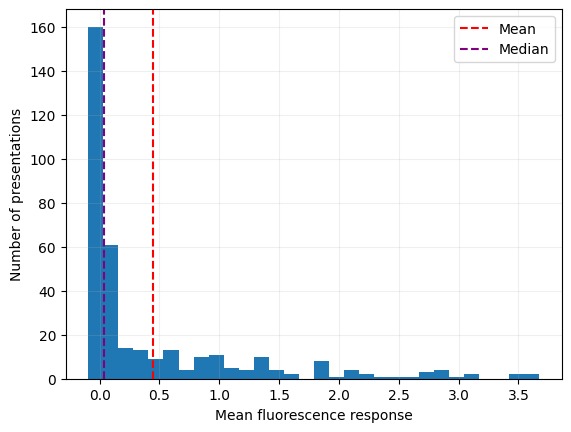

In [233]:
from src.response_matrix import build_response_matrix

X, Y = build_response_matrix(data, 1005018474)

neuron = X.iloc[:, 0]
print(neuron)

plt.hist(neuron, bins=30)
plt.grid(alpha = 0.2)
plt.xlabel('Mean fluorescence response')
plt.ylabel('Number of presentations')
plt.axvline(neuron.mean(), linestyle = '--', color = 'red', label = 'Mean')
plt.axvline(neuron.median(), linestyle = '--', color = 'purple', label = 'Median')
plt.legend()

print('Mean response =',neuron.mean())
print('Median response =',neuron.median())
print('Maximum response =',neuron.max())
print('Minimum response =',neuron.min())
print('Standard deviation =',neuron.std())
print("% below the mean =",neuron[neuron < neuron.mean()].size / neuron.size)


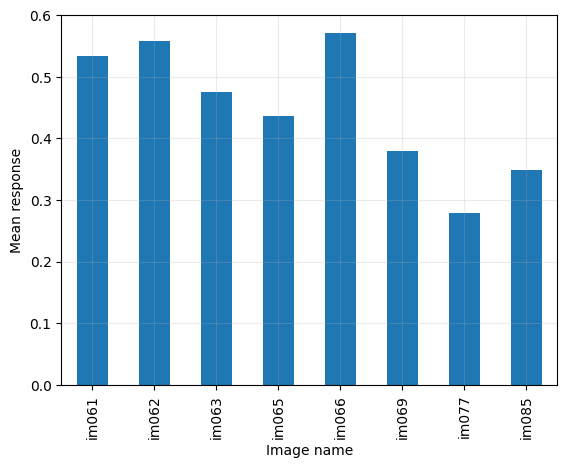

In [234]:
image_names = Y.unique()
mm = []
for image_name in image_names:
    yy = Y[Y == image_name]
    xx = X.loc[yy.index]
    neuron_0 = xx.iloc[:, 0]
    mm.append(neuron_0.mean())
w1 = pd.Series(mm, index = image_names)


xx = X.set_index(Y)
w2 = xx.groupby('Images')[xx.columns[0]].mean()
w2.plot(kind = 'bar')
plt.xlabel('Image name')
plt.ylabel('Mean response')
plt.grid(alpha = 0.25)
plt.show()

        count      mean    median       std
Images                                     
im061      45  0.534200  0.129434  0.850135
im062      46  0.558495  0.037563  0.997888
im063      44  0.474947  0.050040  0.792479
im065      44  0.437027  0.048588  0.827301
im066      42  0.571527  0.076429  0.856638
im069      42  0.379627  0.026795  0.696835
im077      44  0.279576  0.012209  0.506328
im085      45  0.348585  0.015205  0.617575


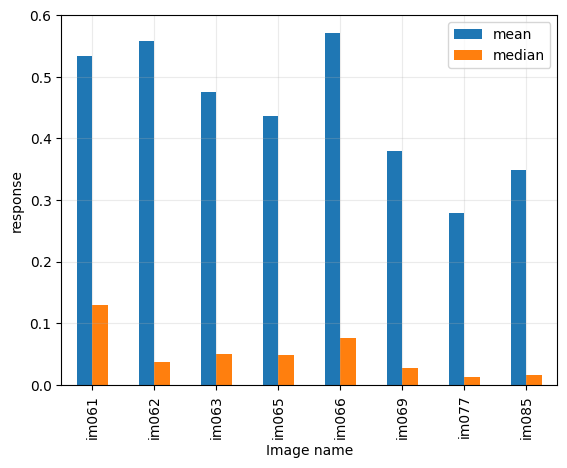

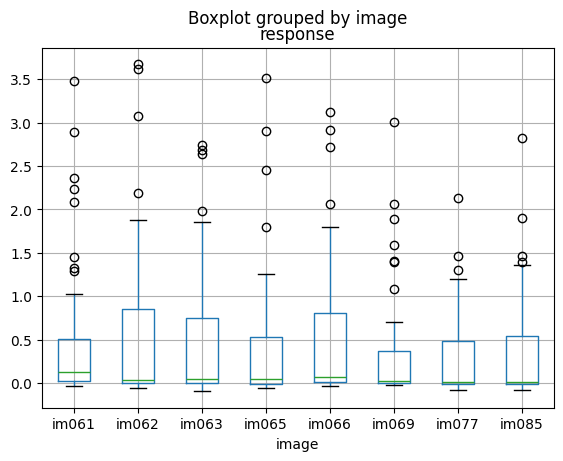

In [240]:
w2 = xx.groupby('Images')[xx.columns[0]].agg(['count', 'mean', 'median', 'std'])
print(w2)
w2[['mean', 'median']].plot(kind='bar')
plt.xlabel('Image name')
plt.ylabel('response')
plt.grid(alpha = 0.25)
plt.show()


df = xx.iloc[:, [0]]
df = df.reset_index()
df.columns = ['image', 'response']
df.boxplot(column = 'response', by = 'image')
plt.show()

For neuron 1086555190, fluorescence responses exhibit pronounced positive asymmetry. Image-conditioned medians are consistently much smaller than means, and the response distributions overlap substantially across image identities. Large positive responses influence the image-conditioned averages. These descriptive findings do not establish whether the neuron exhibits statistically reliable image selectivity.